# Семинар 2. Pipeline, spaCy и Hugging Face Datasets

На прошлом семинаре мы познакомились с базовым NLP-pipeline:

```text
текст → preprocessing → TF-IDF → Logistic Regression
```

Теперь перейдём к новым инструментам и более профессиональной организации NLP-эксперимента.

### План семинара

1. **`sklearn.Pipeline`**
   - зачем объединять preprocessing и модель;
   - как Pipeline помогает избежать ошибок;
   - cross-validation;
   - `GridSearchCV`;
   - подбор гиперпараметров.

2. **spaCy**
   - `nlp`, `Doc`, `Token`, `Span`;
   - леммы и части речи;
   - синтаксические зависимости;
   - Named Entity Recognition.

3. **Hugging Face Datasets**
   - загрузка датасетов;
   - splits;
   - `Dataset`;
   - `IterableDataset`;
   - streaming.

> Главная цель семинара — перейти от отдельных операций над текстом к более цельному и воспроизводимому NLP workflow.


## Локальный запуск

Выберите Python из `.venv` и выполняйте ячейки сверху вниз из папки проекта.
Зависимости и обе модели spaCy зафиксированы в `pyproject.toml` и `uv.lock`;
для восстановления окружения выполните `uv sync` в терминале.
RuTweetCorp читается из `data/positive.csv` и `data/negative.csv`.
Hugging Face при первом запуске загружает датасеты в локальный кеш.

Все сравнения F1 используют **macro-F1**. Разбиения и случайные выборки фиксированы.
Подбор параметров идёт только на train; test используется для итоговых таблиц.
Полные переборы на RuTweetCorp могут занять несколько минут.

Импортируем библиотеки, фиксируем seed и создаём папку для таблиц экспериментов.

In [1]:
from pathlib import Path
from time import perf_counter
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML
from sklearn.base import clone
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_val_score, GridSearchCV,
)
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.preprocessing import FunctionTransformer, MaxAbsScaler
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support, f1_score,
    classification_report, ConfusionMatrixDisplay,
)

pd.set_option('display.max_colwidth', None)

RANDOM_STATE = 42
CV = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
N_JOBS = 1
RESULTS = Path('data/results_nlp02')
RESULTS.mkdir(parents=True, exist_ok=True)

## Данные для примеров

Читаем колонку `ttext` из локальных CSV, добавляем метку класса.
Убираем пропуски и повторяющиеся тексты до разбиения — как в первой лабораторной.
Используем весь корпус, сохраняя одинаковый test для всех экспериментов RuTweetCorp.

In [2]:
def load_rutweet(path, target):
    frame = pd.read_csv(path, usecols=['ttext']).rename(columns={'ttext': 'text'})
    return frame.assign(positive=target)


data = pd.concat([
    load_rutweet('data/positive.csv', 1),
    load_rutweet('data/negative.csv', 0),
], ignore_index=True)
data = data.dropna(subset=['text']).drop_duplicates('text').reset_index(drop=True)

X_train, X_test, y_train, y_test = train_test_split(
    data['text'], data['positive'], test_size=0.2,
    stratify=data['positive'], random_state=RANDOM_STATE,
)
print('Train:', X_train.shape, '| Test:', X_test.shape)
display(data['positive'].value_counts().sort_index().rename('count'))

Train: (173952,) | Test: (43488,)


positive
0    107044
1    110396
Name: count, dtype: int64

## 1. Зачем нужен Pipeline?

До сих пор мы писали:

```python
tfidf.fit_transform(X_train)
model.fit(...)
tfidf.transform(X_test)
model.predict(...)

TRAIN:
fit → transform → fit model

TEST:
transform → predict
```

Это полезно для понимания механики.

Но в реальном ML-проекте появляется риск:

- случайно сделать `fit` на test;
- применить разные преобразования к train и test;
- запутаться при cross-validation; - Вопрос что это такое?
- забыть один из шагов при inference.

`Pipeline` объединяет преобразования и модель в **один объект**.

Объединяем TF-IDF и логистическую регрессию в один Pipeline.

In [3]:
classifier = Pipeline([
    ('vectorizer', TfidfVectorizer(min_df=2)),
    ('model', LogisticRegression(
        solver='liblinear', max_iter=1000, random_state=RANDOM_STATE,
    )),
])
classifier

,steps,"[('vectorizer', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,input,'content'
,encoding,'utf-8'
,decode_error,'strict'
,strip_accents,None
,lowercase,True
,preprocessor,None
,tokenizer,None


Теперь весь процесс выглядит так:

```text
raw text
   ↓
TfidfVectorizer
   ↓
LogisticRegression
```

И снаружи мы работаем с ним как с обычной моделью.

Обучаем исходный Pipeline и измеряем macro-F1 на отложенном test.

In [4]:
classifier.fit(X_train, y_train)
pipeline_pred = classifier.predict(X_test)
pipeline_test_f1 = f1_score(y_test, pipeline_pred, average='macro')
print(f'Test macro-F1: {pipeline_test_f1:.4f}')

Test macro-F1: 0.7563


## 2. Cross-validation

Кросс-валидация — это несколько внутренних проверок на train-данных.

Один train/test split зависит от конкретного разбиения данных.

Cross-validation несколько раз меняет validation-часть:

```text
Fold 1: train train train train | valid
Fold 2: train train train valid | train
Fold 3: train train valid train | train
...
```
```text
Допустим, у нас есть 12 объектов.

Fold 1: [1 2 3 4]       → validation
        [5 6 7 8 9 10 11 12] → train

Fold 2: [5 6 7 8]       → validation
        остальные       → train

Fold 3: [9 10 11 12]    → validation
        остальные       → train
```
В результате мы получаем более устойчивую оценку качества.

Оцениваем Pipeline на трёх одинаковых стратифицированных folds.

In [5]:
cv_scores = cross_val_score(
    classifier, X_train, y_train, scoring='f1_macro', cv=CV, n_jobs=N_JOBS,
)
print('F1 по folds:', cv_scores.round(4))
print(f'Средний F1: {cv_scores.mean():.4f}; std: {cv_scores.std():.4f}')

F1 по folds: [0.7437 0.7437 0.7455]
Средний F1: 0.7443; std: 0.0009


### Зачем смотреть стандартное отклонение?

Две модели могут иметь одинаковый средний F1:

```text
Model 1: 0.91 ± 0.01
Model 2: 0.91 ± 0.08
```

Но первая модель работает значительно **стабильнее** на разных разбиениях.

## 3. GridSearchCV

**GridSearchCV - Метод автоматического подбора гиперпараметров модели, который перебирает заданные комбинации параметров и оценивает каждую из них с помощью cross-validation.**


У модели и preprocessing есть гиперпараметры.

Например:

### `TfidfVectorizer`

- `ngram_range` — какие n-граммы использовать.  
  `(1, 1)` — только отдельные слова, `(1, 2)` — слова + пары слов.

- `min_df` — минимальное количество документов, в которых должен встретиться термин, чтобы попасть в словарь.  
  Помогает убрать очень редкие слова.

- `max_df` — максимальная доля документов, в которых может встречаться термин.  
  Помогает убрать слишком частые, малоинформативные слова.

### `LogisticRegression`

- `C` — обратная сила регуляризации.  
  Чем меньше `C`, тем сильнее регуляризация.

- `penalty` — тип регуляризации: например `l1` или `l2`.

- `solver` — алгоритм оптимизации, который ищет веса модели.

### Важный момент про `C`

В `LogisticRegression`:

```text
маленький C → сильнее регуляризация
большой C   → слабее регуляризация
```

Регуляризация ограничивает слишком большие коэффициенты модели и помогает бороться с переобучением.

Задаём сетку n-грамм, регуляризации и C; все преобразования обучаются внутри CV.

In [6]:
grid_pipeline = clone(classifier)
param_grid = {
    'vectorizer__ngram_range': [(1, 1), (1, 2)],
    'model__C': [0.3, 1.0, 3.0],
    'model__penalty': ['l1', 'l2'],
}
grid = GridSearchCV(
    grid_pipeline, param_grid, scoring='f1_macro', cv=CV,
    n_jobs=N_JOBS, refit=True, return_train_score=False,
)

> На учебном ноутбуке grid специально небольшой.

В реальном проекте не стоит бездумно запускать огромный перебор: - Кто скажет почему?

```text
10 параметров × 10 значений × 5 folds
```


Запускаем исходный перебор, сохраняем длительность и лучший CV macro-F1.

In [7]:
started = perf_counter()
grid.fit(X_train, y_train)
grid_seconds = perf_counter() - started
print('Лучшие параметры:', grid.best_params_)
print(f'CV macro-F1: {grid.best_score_:.4f}; время: {grid_seconds:.1f} с')

Лучшие параметры: {'model__C': 3.0, 'model__penalty': 'l2', 'vectorizer__ngram_range': (1, 2)}
CV macro-F1: 0.7572; время: 182.0 с


Оцениваем выбранную по CV модель на test.

In [8]:
best_pred = grid.predict(X_test)
grid_test_f1 = f1_score(y_test, best_pred, average='macro')
print(f'Test macro-F1: {grid_test_f1:.4f}')

Test macro-F1: 0.7669


### Задание

Попробуйте добавить в `param_grid`:

```python
'vectorizer__min_df': [1, 2, 5]
```

Ответьте:

1. какой набор параметров оказался лучшим;
2. насколько изменился F1;
3. стоит ли усложнение модели полученного прироста?

Шаг 1. Добавляем `min_df = 1 / 2 / 5` и повторяем подбор на тех же folds.

In [9]:
param_grid_min_df = {**param_grid, 'vectorizer__min_df': [1, 2, 5]}
grid_min_df = GridSearchCV(
    grid_pipeline, param_grid_min_df, scoring='f1_macro', cv=CV,
    n_jobs=N_JOBS, refit=True,
)
started = perf_counter()
grid_min_df.fit(X_train, y_train)
min_df_seconds = perf_counter() - started
print('Лучшие параметры:', grid_min_df.best_params_)

Лучшие параметры: {'model__C': 3.0, 'model__penalty': 'l2', 'vectorizer__min_df': 2, 'vectorizer__ngram_range': (1, 2)}


Шаги 2–3. Сравниваем CV/test F1, время перебора и размер словаря — данные для оценки прироста и сложности.

In [10]:
min_df_test_f1 = f1_score(y_test, grid_min_df.predict(X_test), average='macro')
grid_comparison = pd.DataFrame([
    {'search': 'исходная сетка', 'cv_f1': grid.best_score_,
     'test_f1': grid_test_f1, 'seconds': grid_seconds,
     'vocabulary': len(grid.best_estimator_['vectorizer'].vocabulary_)},
    {'search': '+ min_df', 'cv_f1': grid_min_df.best_score_,
     'test_f1': min_df_test_f1, 'seconds': min_df_seconds,
     'vocabulary': len(grid_min_df.best_estimator_['vectorizer'].vocabulary_)},
]).set_index('search')
display(grid_comparison.round(4))
print('Изменение CV F1:', round(grid_min_df.best_score_ - grid.best_score_, 4))
print('Изменение test F1:', round(min_df_test_f1 - grid_test_f1, 4))
grid_comparison.to_csv(RESULTS / 'min_df_comparison.csv')

,cv_f1,test_f1,seconds,vocabulary
search,,,,
исходная сетка,0.7572,0.7669,181.9819,227650
+ min_df,0.7572,0.7669,854.1363,227650


Изменение CV F1: 0.0
Изменение test F1: 0.0


---
# Часть 2. spaCy: текст как структурированный объект

До сих пор мы в основном работали с текстом как со строкой:

```python
"Я люблю обработку естественного языка"
```

Но в NLP часто нужно знать больше:

- где находятся токены;
- какая у слова лемма;
- какая часть речи;
- от какого слова оно зависит;
- является ли фрагмент именованной сущностью.

Для таких задач удобно использовать **spaCy**.

bcdfffe5c0b9f221a2f6607f96ca0e4a.svg




## 4. Русский pipeline spaCy

Модель установлена в локальном окружении. Загружаем её и смотрим этапы обработки.

In [11]:
import spacy

nlp = spacy.load('ru_core_news_sm')

print(nlp.pipe_names)

['tok2vec', 'morphologizer', 'parser', 'attribute_ruler', 'lemmatizer', 'ner']


## 5. `nlp` и `Doc`

`nlp` — объект, который содержит pipeline обработки текста.

Передаём ему строку:

```python
doc = nlp(text)
```

и получаем объект `Doc`.

Обрабатываем предложение и получаем объект Doc с последовательностью токенов.

In [12]:
doc = nlp(
    'Студенты изучают обработку естественного языка в университете.'
)

print(type(doc))

for token in doc:
    print(token.text)

<class 'spacy.tokens.doc.Doc'>
Студенты
изучают
обработку
естественного
языка
в
университете
.


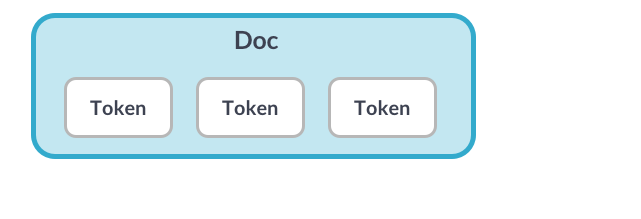

## 6. `Token`

`Doc` можно представить как последовательность токенов.

Каждый `Token` содержит не только текст слова, но и множество дополнительных атрибутов.

Смотрим основные атрибуты первого токена.

In [13]:
token = doc[0]

print('text      =', token.text)
print('lemma     =', token.lemma_)
print('POS       =', token.pos_)
print('is_alpha  =', token.is_alpha)
print('is_punct  =', token.is_punct)
print('like_num  =', token.like_num)

text      = Студенты
lemma     = студент
POS       = NOUN
is_alpha  = True
is_punct  = False
like_num  = False


### Что означают атрибуты `Token`

- `token.text` — исходный текст токена.
- `token.lemma_` — лемма, то есть нормальная форма слова.
- `token.pos_` — часть речи: существительное, глагол, прилагательное и т.д.
- `token.is_alpha` — состоит ли токен только из букв.
- `token.is_punct` — является ли токен знаком пунктуации.
- `token.like_num` — похож ли токен на число.

### Задание

Выведите для каждого токена:

```text
text
lemma_
pos_
is_stop
```

Какие слова spaCy считает стоп-словами?

Показываем текст, лемму, POS и признак стоп-слова для каждого токена.

In [14]:
display(pd.DataFrame([
    {'text': t.text, 'lemma_': t.lemma_, 'pos_': t.pos_, 'is_stop': t.is_stop}
    for t in doc
]))
print('Стоп-слова:', [t.text for t in doc if t.is_stop])

,text,lemma_,pos_,is_stop
0,Студенты,студент,NOUN,False
1,изучают,изучать,VERB,False
2,обработку,обработка,NOUN,False
3,естественного,естественный,ADJ,False
4,языка,язык,NOUN,False
5,в,в,ADP,True
6,университете,университет,NOUN,False
7,.,.,PUNCT,False


Стоп-слова: ['в']


## 7. `Span`

`Span` — это срез `Doc`, содержащий несколько токенов.

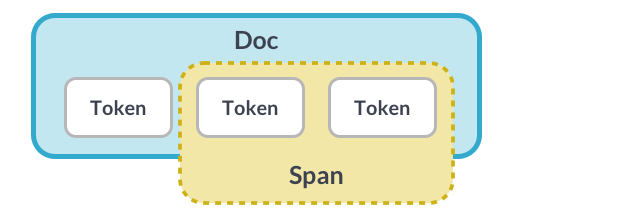

Выделяем Span срезом Doc.

In [15]:
span = doc[2:5]

print(span.text)
print(type(span))

обработку естественного языка
<class 'spacy.tokens.span.Span'>


## 8. Лемматизация и части речи

В первом семинаре мы использовали отдельный инструмент для лемматизации.

spaCy позволяет одновременно получить:

```text
токен → лемма → часть речи
```

Выводим леммы и части речи слов предложения.

In [16]:
doc = nlp(
    'Красивые машины быстро ехали по заснеженной дороге.'
)

for token in doc:
    print(
        f'{token.text:15}',
        f'{token.lemma_:15}',
        token.pos_
    )

Красивые        красивый        ADJ
машины          машина          NOUN
быстро          быстро          ADV
ехали           ехать           VERB
по              по              ADP
заснеженной     заснеженной     VERB
дороге          дорога          NOUN
.               .               PUNCT


### Основные значения `POS`

1. `NOUN` — существительное  
2. `VERB` — глагол  
3. `ADJ` — прилагательное  
4. `ADV` — наречие  
5. `PRON` — местоимение  
6. `PROPN` — имя собственное  
7. `NUM` — числительное  
8. `PUNCT` — пунктуация

## 9. Синтаксические зависимости

`dep_` показывает синтаксическое отношение слова.

`head` — слово, от которого текущий токен зависит.

Показываем тип зависимости и главное слово каждого токена.

In [17]:
doc = nlp(
    'Студенты внимательно слушают преподавателя.'
)

for token in doc:
    print(
        token.text,
        '→',
        token.dep_,
        '→ head:',
        token.head.text
    )

Студенты → nsubj → head: слушают
внимательно → advmod → head: слушают
слушают → ROOT → head: слушают
преподавателя → obj → head: слушают
. → punct → head: слушают


## Шпаргалка: `POS` и `dep_` в spaCy

### Части речи — `token.pos_`

| Обозначение | Значение | Пример |
|---|---|---|
| `NOUN` | существительное | `студент`, `машина` |
| `VERB` | глагол | `слушать`, `ехать` |
| `ADJ` | прилагательное | `красивый`, `быстрый` |
| `ADV` | наречие | `внимательно`, `быстро` |
| `PRON` | местоимение | `я`, `он`, `они` |
| `PROPN` | имя собственное | `Москва`, `Яндекс` |
| `NUM` | числительное | `один`, `12` |
| `PUNCT` | пунктуация | `.`, `,`, `!` |

---

### Синтаксические зависимости — `token.dep_`

| Обозначение | Значение | Пример |
|---|---|---|
| `ROOT` | главное слово предложения | `слушают` |
| `nsubj` | подлежащее | `Студенты → слушают` |
| `obj` | дополнение | `преподавателя → слушают` |
| `advmod` | обстоятельство / наречный модификатор | `внимательно → слушают` |
| `amod` | определение-прилагательное | `красивый → дом` |
| `nmod` | именная модификация | `студента → книга` |
| `obl` | обстоятельственное дополнение | `в Москву → ехать` |
| `case` | предлог / показатель падежной связи | `в → Москву` |
| `conj` | однородный член | `кофе → чай` |
| `cc` | сочинительный союз | `и`, `или`, `но` |
| `aux` | вспомогательный глагол | вспомогательная глагольная форма |
| `cop` | глагол-связка | `быть`, `являться` |
| `mark` | подчинительный союз | `что`, `если`, `когда` |
| `punct` | знак пунктуации | `.`, `,`, `!` |
| `xcomp` | зависимая конструкция без собственного подлежащего | `хочу работать` |
| `ccomp` | придаточная часть с собственным подлежащим | `знаю, что он придёт` |

> `token.pos_` отвечает на вопрос **«какая это часть речи?»**  
> `token.dep_` отвечает на вопрос **«какую синтаксическую роль этот токен играет?»**  
> `token.head` показывает, **от какого слова он зависит**.

Рисуем синтаксические зависимости средствами displaCy.

In [18]:
from spacy import displacy

display(HTML(displacy.render(doc, style='dep', jupyter=False, options={'compact': True})))

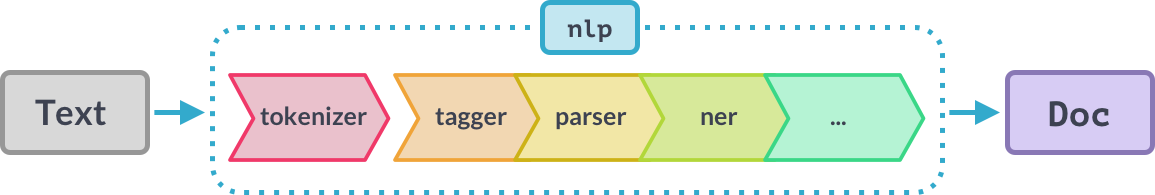

## 10. Named Entity Recognition

NER — задача поиска сущностей в тексте.

Например:

```text
Москва      → LOC
Александр   → PER
Сбербанк    → ORG
```

Находим именованные сущности и расшифровываем их типы.

In [19]:
doc = nlp(
    'Александр приехал из Москвы и устроился работать в Яндекс.'
)

for ent in doc.ents:
    print(
        ent.text,
        ent.label_,
        spacy.explain(ent.label_)
    )

Александр PER Named person or family.
Москвы LOC Non-GPE locations, mountain ranges, bodies of water
Яндекс ORG Companies, agencies, institutions, etc.


Подсвечиваем сущности в исходном предложении.

In [20]:
display(HTML(displacy.render(doc, style='ent', jupyter=False)))

### Задание

Возьмите любое короткое новостное предложение и:

1. найдите все токены;
2. выведите леммы;
3. выведите части речи;
4. найдите именованные сущности;
5. визуализируйте зависимости.

Шаг 1. Разбираем учебное новостное предложение и выводим токены.

In [21]:
news_doc = nlp('Компания Яндекс открыла новый офис в Москве.')
print([t.text for t in news_doc])

['Компания', 'Яндекс', 'открыла', 'новый', 'офис', 'в', 'Москве', '.']


Шаг 2. Выводим леммы.

In [22]:
print([t.lemma_ for t in news_doc])

['компания', 'яндекс', 'открыть', 'новый', 'офис', 'в', 'москва', '.']


Шаг 3. Сопоставляем каждому токену часть речи.

In [23]:
display(pd.DataFrame([(t.text, t.pos_) for t in news_doc], columns=['token', 'POS']))

,token,POS
0,Компания,NOUN
1,Яндекс,PROPN
2,открыла,VERB
3,новый,ADJ
4,офис,NOUN
5,в,ADP
6,Москве,PROPN
7,.,PUNCT


Шаг 4. Выводим найденные сущности и их типы.

In [24]:
display(pd.DataFrame([(e.text, e.label_) for e in news_doc.ents], columns=['entity', 'type']))

,entity,type
0,Яндекс,ORG
1,Москве,LOC


Шаг 5. Визуализируем зависимости.

In [25]:
display(HTML(displacy.render(news_doc, style='dep', jupyter=False, options={'compact': True})))

### Что важно понять про spaCy

spaCy не заменяет TF-IDF или классификатор.

Это другой уровень NLP-инструментария.


TF-IDF
→ статистическая мера, которая показывает, насколько важно слово для конкретного документа внутри большого набора документов (корпуса). Знание меры позволяет базово векторизвать текст

spaCy
→ структурированный лингвистический анализ текста в котором учитывается не только частота, а так же морфологический, лингвистический анализ и взаимосвязи слов в тексте


В реальном проекте эти подходы могут использоваться вместе.
### Список типов именованных сущностей

Полное описание Named Entity Recognition и основных типов сущностей можно посмотреть в официальной документации spaCy:

[spaCy — Named Entity Recognition](https://spacy.io/usage/linguistic-features#named-entities)

Например:

- `PER` / `PERSON` — человек;
- `ORG` — организация;
- `LOC` — географическая локация;
- `GPE` — страна, город, регион;
- `MONEY` — денежное значение;
- `DATE` — дата;
- `TIME` — время.

> Набор доступных `label` зависит от конкретной языковой модели spaCy.

---
# Часть 3. Hugging Face Datasets

# Hugging Face Datasets

Официальная документация библиотеки:

[Hugging Face Datasets — Documentation](https://huggingface.co/docs/datasets/index)

Полезные разделы:

- [Loading datasets](https://huggingface.co/docs/datasets/loading)
- [Dataset object](https://huggingface.co/docs/datasets/package_reference/main_classes#datasets.Dataset)
- [Streaming](https://huggingface.co/docs/datasets/stream)

## 11. Зачем Hugging Face?

До сих пор датасеты лежали у нас локально:

```text
positive.csv
negative.csv
```

Но в ML существует большое количество публичных датасетов и моделей.

**Hugging Face** — одна из основных платформ современной NLP/ML-экосистемы.

Библиотека `datasets` позволяет:

- находить и загружать датасеты;
- работать со splits-отдельные части тренировочной/валидационной/тестовой выборки;
- быстро применять преобразования;
- читать большие датасеты потоково.

## 12. Смотрим описание датасета до загрузки

Получаем описание, схему и метки Rotten Tomatoes до чтения строк.

In [2]:
from datasets import load_dataset_builder, load_dataset, get_dataset_split_names

RT_REVISION = 'aa13bc287fa6fcab6daf52f0dfb9994269ffea28'
EMOTION_REVISION = 'cab853a1dbdf4c42c2b3ef2173804746df8825fe'
RT_ID = 'cornell-movie-review-data/rotten_tomatoes'
builder = load_dataset_builder(RT_ID, revision=RT_REVISION)
print(builder.info.description[:1000])
print(builder.info.features)


{'text': Value('string'), 'label': ClassLabel(names=['neg', 'pos'])}


## 13. Загружаем Dataset

Загружаем train с корректным идентификатором датасета.

In [27]:
dataset = load_dataset(RT_ID, revision=RT_REVISION, split='train')
dataset

Dataset({
    features: ['text', 'label'],
    num_rows: 8530
})

Получаем одну запись по индексу.

In [28]:
dataset[0]

{'text': 'the rock is destined to be the 21st century\'s new " conan " and that he\'s going to make a splash even greater than arnold schwarzenegger , jean-claud van damme or steven segal .',
 'label': 1}

Получаем первые три записи срезом.

In [29]:
dataset[:3]

{'text': ['the rock is destined to be the 21st century\'s new " conan " and that he\'s going to make a splash even greater than arnold schwarzenegger , jean-claud van damme or steven segal .',
  'the gorgeously elaborate continuation of " the lord of the rings " trilogy is so huge that a column of words cannot adequately describe co-writer/director peter jackson\'s expanded vision of j . r . r . tolkien\'s middle-earth .',
  'effective but too-tepid biopic'],
 'label': [1, 1, 1]}

`Dataset` похож на таблицу, но оптимизирован для ML-задач.

Можно получать:

- отдельную строку;
- срез;
- столбец;
- применять преобразования через `.map()`.

## 14. Splits

У ML-датасета часто уже есть:

```text
train
validation
test
```

Проверяем готовые train/validation/test splits.

In [30]:
get_dataset_split_names(RT_ID, revision=RT_REVISION)

['train', 'validation', 'test']

### Почему готовые splits полезны?

Если авторы датасета заранее зафиксировали train/test:

- эксперименты разных людей легче сравнивать;
- уменьшается вероятность случайно получить «удобное» разбиение;
- benchmark становится воспроизводимым.

## 15. Dataset → pandas

Преобразуем первые 100 записей в pandas.

In [31]:
small_dataset = dataset.select(range(100))

df_hf = small_dataset.to_pandas()

df_hf.head()

,text,label
0,the rock is destined to be the 21st century's ...,1
1,"the gorgeously elaborate continuation of "" the...",1
2,effective but too-tepid biopic,1
3,if you sometimes like to go to the movies to h...,1
4,"emerges as something rare , an issue movie tha...",1


То есть Hugging Face Datasets не отменяет привычный `pandas`.

Обычно мы выбираем инструмент под задачу:

```text
pandas
→ табличный анализ и EDA

datasets.Dataset
→ ML/NLP pipeline и большие наборы данных
```

## 16. `IterableDataset`

Обычный `Dataset` предоставляет произвольный доступ:

```python
dataset[100]
```

Но очень большой датасет может не помещаться в память.

Тогда используется потоковая обработка:

```text
данные → по одному объекту → обработка
```

Перебираем три записи через IterableDataset; исходный Dataset уже загружен локально.

In [32]:
iterable_dataset = dataset.to_iterable_dataset()

first_three = list(iterable_dataset.take(3))

first_three

[{'text': 'the rock is destined to be the 21st century\'s new " conan " and that he\'s going to make a splash even greater than arnold schwarzenegger , jean-claud van damme or steven segal .',
  'label': 1},
 {'text': 'the gorgeously elaborate continuation of " the lord of the rings " trilogy is so huge that a column of words cannot adequately describe co-writer/director peter jackson\'s expanded vision of j . r . r . tolkien\'s middle-earth .',
  'label': 1},
 {'text': 'effective but too-tepid biopic', 'label': 1}]

В реальном streaming-сценарии датасет можно читать с удалённого источника, не загружая его полностью.

Это особенно полезно для:

- больших корпусов;
- обучения language models;
- пайплайнов, где данные обрабатываются последовательно.

### Задание

Для любого другого датасета из пространства Hugging Face:

1. получите список доступных splits;
2. загрузите `test`;
3. выведите 5 случайных текстов;
4. посмотрите распределение `label`;


Шаг 1. Для другого датасета — Emotion — получаем список splits и описание классов.

In [3]:
EMOTION_ID = 'dair-ai/emotion'
print(get_dataset_split_names(EMOTION_ID, 'split', revision=EMOTION_REVISION))
emotion_builder = load_dataset_builder(EMOTION_ID, 'split', revision=EMOTION_REVISION)
label_names = emotion_builder.info.features['label'].names
print(dict(enumerate(label_names)))

['train', 'validation', 'test']


{0: 'sadness', 1: 'joy', 2: 'love', 3: 'anger', 4: 'fear', 5: 'surprise'}


Шаг 2. Загружаем официальный test.

In [4]:
emotion_test = load_dataset(EMOTION_ID, 'split', revision=EMOTION_REVISION, split='test')
emotion_test

Dataset({
    features: ['text', 'label'],
    num_rows: 2000
})

Шаг 3. Выводим пять случайных текстов с расшифрованными метками.

In [5]:
emotion_test_df = emotion_test.to_pandas()
examples = emotion_test_df.sample(5, random_state=RANDOM_STATE).copy()
examples['class'] = examples['label'].map(dict(enumerate(label_names)))
display(examples[['text', 'class']])

,text,class
1860,i feel so dirty but after spending a day at the mk show me and a buddy decided we would get the two player starter between us luckily for us both i liked the everblight and he liked the circle maybe a tad to much so it all worked out well,sadness
353,i could feel his breath on me and smell the sweet scent of him,joy
1333,i just want to feel loved by you,love
905,i have felt the need to write out my sometimes anxious feelings impatient thoughts lists of things that still should could be done before this baby arrives,anger
1289,at a party i met a girl who drew me to her,anger


Шаг 4. Считаем число и долю объектов каждого класса в test.

In [36]:
test_distribution = emotion_test_df['label'].value_counts().reindex(range(len(label_names)))
display(pd.DataFrame({
    'count': test_distribution.values,
    'share': test_distribution.values / len(emotion_test_df),
}, index=label_names))

,count,share
sadness,581,0.2905
joy,695,0.3475
love,159,0.0795
anger,275,0.1375
fear,224,0.1120
surprise,66,0.0330


# Работа на дом

### Задание 1. Улучшите baseline

Для RuTweetCorp соберите `Pipeline`:

```text
TfidfVectorizer → LogisticRegression
```
Разделите признаки при preprocessing

Разделите признаки на два блока:

- **текстовые** → слова и n-граммы → `TF-IDF`;
- **эмоциональные** → смайлики, скобки, `!`, `?`, CAPS, повторяющаяся пунктуация.

Эмоциональные признаки представьте отдельно как числовые значения и масштабируйте, например через `MaxAbsScaler`.

После этого объедините оба блока:

```text
TF-IDF текста
+
масштабированные emotion-features
→ LogisticRegression

Дополнительно попробуйте несколько весов эмоционального блока, например:
0.1 / 0.3 / 0.5 / 1.0

и выберите значение по cross-validation.
Цель — не удалить эмоциональные признаки, но и не позволить модели полностью опираться только на них.
```

и сравните минимум 3 конфигурации при обучении.

Попробуйте менять:

- `ngram_range`;
- `min_df`;
- `C`.

Для каждого эксперимента сохраните:

- CV F1;
- test F1;
- параметры.

В конце укажите:

- лучшие найденные гиперпараметры;
- лучший CV F1;
- F1 на test;
- короткий вывод о том, что изменилось относительно baseline из первой лабораторной.

---

Шаг 1. Разделяем слова и эмоциональные признаки.

Из текстового блока исключаем URL, упоминания и смайлики; оставляем слова.
В числовой блок передаём признаки исходной строки: смайлики, скобки,
восклицательные/вопросительные знаки, долю CAPS и серии пунктуации.

In [37]:
def clean_tweet(text):
    text = re.sub(r'https?://\S+|@\w+', ' ', text)
    text = re.sub(r'[:;=8xX][\-^\']?[)(/\\dDpP]+|[<♥❤]3?', ' ', text)
    return ' '.join(re.findall(r'[а-яёa-z]+', text.lower()))


emotion_columns = [
    'smile', 'sad', 'open_brackets', 'close_brackets',
    'exclamation', 'question', 'caps_share', 'repeated_punctuation',
]


def emotion_features(texts):
    rows = []
    for text in texts:
        letters = [c for c in text if c.isalpha()]
        rows.append([
            len(re.findall(r'[:;=8][\-^]?[)dD]+|<3|[♥❤]', text)),
            len(re.findall(r'[:;=8][\-^]?[(\/\\]+', text)),
            text.count('('), text.count(')'), text.count('!'), text.count('?'),
            sum(c.isupper() for c in letters) / max(len(letters), 1),
            len(re.findall(r'[!?.,:;()]{2,}', text)),
        ])
    return np.asarray(rows, dtype=float)


display(pd.DataFrame(emotion_features(X_train.head()), columns=emotion_columns)
        .assign(text=X_train.head().to_numpy()))

,smile,sad,open_brackets,close_brackets,exclamation,question,caps_share,repeated_punctuation,text
0,0.0,0.0,2.0,0.0,0.0,0.0,0.095238,1.0,RT @iqirnoyrba: RT @ejasergey: RT @NataliyaGri...
1,0.0,1.0,5.0,0.0,0.0,0.0,0.250000,2.0,РАССКАЖИ ЧТО-ТО ((9(9(( — Нечего рассказывать ...
2,2.0,0.0,0.0,6.0,0.0,1.0,0.025974,3.0,@GoLevers доброе:))) а что плохого в пятнице 1...
3,0.0,1.0,3.0,0.0,0.0,0.0,0.012346,1.0,"Так хотелось бы есть мандаринки, смотреть филь..."
4,0.0,0.0,0.0,1.0,0.0,0.0,0.024691,0.0,"@Kety_Leto меня вынесло почему-то ахах\nнет, е..."


Шаг 2. Масштабируем числовые признаки внутри Pipeline и объединяем с TF-IDF через FeatureUnion.

In [38]:
tweet_features = FeatureUnion([
    ('text', TfidfVectorizer(preprocessor=clean_tweet, lowercase=False)),
    ('emotion', Pipeline([
        ('extract', FunctionTransformer(emotion_features)),
        ('scale', MaxAbsScaler()),
    ])),
])
emotion_pipeline = Pipeline([
    ('features', tweet_features),
    ('model', LogisticRegression(solver='liblinear', max_iter=1000, random_state=RANDOM_STATE)),
])

Шаг 3. Сравниваем три конфигурации текста и C, каждую с четырьмя весами эмоций.
Всего 12 экспериментов; лучшую комбинацию выбираем только по CV macro-F1.

In [39]:
text_configs = [
    ((1, 1), 2, 0.3),
    ((1, 2), 2, 1.0),
    ((1, 2), 5, 3.0),
]
emotion_grid = [
    {
        'features__text__ngram_range': [ngrams],
        'features__text__min_df': [min_df],
        'model__C': [C],
        'features__transformer_weights': [
            {'text': 1.0, 'emotion': weight} for weight in [0.1, 0.3, 0.5, 1.0]
        ],
    }
    for ngrams, min_df, C in text_configs
]
emotion_search = GridSearchCV(
    emotion_pipeline, emotion_grid, scoring='f1_macro', cv=CV,
    n_jobs=N_JOBS, refit=True,
)
emotion_search.fit(X_train, y_train)
print('Лучшие параметры:', emotion_search.best_params_)
print(f'Лучший CV macro-F1: {emotion_search.best_score_:.4f}')

Лучшие параметры: {'features__text__min_df': 5, 'features__text__ngram_range': (1, 2), 'features__transformer_weights': {'text': 1.0, 'emotion': 1.0}, 'model__C': 3.0}
Лучший CV macro-F1: 0.9752


Шаг 4. После выбора по CV оцениваем каждую конфигурацию на общем test.
Сохраняем CV F1, test F1, отклонение CV и параметры в CSV.

In [40]:
experiment_rows = []
for params, cv_f1, cv_std in zip(
    emotion_search.cv_results_['params'],
    emotion_search.cv_results_['mean_test_score'],
    emotion_search.cv_results_['std_test_score'],
):
    estimator = clone(emotion_pipeline).set_params(**params).fit(X_train, y_train)
    experiment_rows.append({
        'ngram_range': params['features__text__ngram_range'],
        'min_df': params['features__text__min_df'],
        'C': params['model__C'],
        'emotion_weight': params['features__transformer_weights']['emotion'],
        'cv_f1': cv_f1, 'cv_std': cv_std,
        'test_f1': f1_score(y_test, estimator.predict(X_test), average='macro'),
    })
emotion_results = pd.DataFrame(experiment_rows).sort_values('cv_f1', ascending=False)
emotion_results.to_csv(RESULTS / 'rutweet_experiments.csv', index=False)
display(emotion_results.round(4))

,ngram_range,min_df,C,emotion_weight,cv_f1,cv_std,test_f1
11,"(1, 2)",5,3.0,1.0,0.9752,0.0014,0.9788
7,"(1, 2)",2,1.0,1.0,0.9645,0.0022,0.9701
10,"(1, 2)",5,3.0,0.5,0.9400,0.0049,0.9504
3,"(1, 1)",2,0.3,1.0,0.9336,0.0060,0.9450
6,"(1, 2)",2,1.0,0.5,0.9144,0.0081,0.9269
9,"(1, 2)",5,3.0,0.3,0.8952,0.0097,0.9084
2,"(1, 1)",2,0.3,0.5,0.8669,0.0120,0.8797
5,"(1, 2)",2,1.0,0.3,0.8654,0.0117,0.8770
1,"(1, 1)",2,0.3,0.3,0.8193,0.0105,0.8295
8,"(1, 2)",5,3.0,0.1,0.7943,0.0085,0.8053


Шаг 5. Для выбранных по CV параметров проверяем вклад эмоций, обучая тот же текстовый блок отдельно.
Сравниваем с исходным Pipeline и сохранённым результатом первой лабораторной.
Матрица первой лабораторной взята из её выполненной ячейки; заново её модель здесь не обучается.
В первой работе использованы Mystem, русские стоп-слова, `min_df=2`, `max_df=0.95`, `max_features=100000`.
Состав корпуса и разбиение совпадают; новый текстовый preprocessing отличается.

In [41]:
best_emotion = emotion_search.best_estimator_
emotion_test_f1 = f1_score(y_test, best_emotion.predict(X_test), average='macro')
text_only = Pipeline([
    ('vectorizer', clone(best_emotion['features'].transformer_list[0][1])),
    ('model', clone(best_emotion['model'])),
])
text_only_cv = cross_val_score(text_only, X_train, y_train, scoring='f1_macro', cv=CV, n_jobs=N_JOBS)
text_only.fit(X_train, y_train)
text_only_test_f1 = f1_score(y_test, text_only.predict(X_test), average='macro')

lab1_cm = np.array([[14635, 6774], [5515, 16564]])
lab1_f1 = np.mean(2 * lab1_cm.diagonal() / (lab1_cm.sum(axis=0) + lab1_cm.sum(axis=1)))
assert lab1_cm.sum() == len(y_test)
tweet_comparison = pd.DataFrame([
    {'model': 'Лаб. 1 (сохранённый результат)', 'cv_f1': np.nan, 'test_f1': lab1_f1},
    {'model': 'Исходный Pipeline', 'cv_f1': cv_scores.mean(), 'test_f1': pipeline_test_f1},
    {'model': 'Текст без эмоций (те же параметры)', 'cv_f1': text_only_cv.mean(), 'test_f1': text_only_test_f1},
    {'model': 'Текст + эмоции (выбор по CV)', 'cv_f1': emotion_search.best_score_, 'test_f1': emotion_test_f1},
]).set_index('model')
display(tweet_comparison.round(4))
print('Δ test macro-F1 к лабораторной 1:', round(emotion_test_f1 - lab1_f1, 4))
print('Δ test macro-F1 от добавления эмоций:', round(emotion_test_f1 - text_only_test_f1, 4))
tweet_comparison.to_csv(RESULTS / 'rutweet_comparison.csv')

,cv_f1,test_f1
model,,
Лаб. 1 (сохранённый результат),NaN,0.7169
Исходный Pipeline,0.7443,0.7563
Текст без эмоций (те же параметры),0.7332,0.7422
Текст + эмоции (выбор по CV),0.9752,0.9788


Δ test macro-F1 к лабораторной 1: 0.262
Δ test macro-F1 от добавления эмоций: 0.2366


### Задание 2. Анализ нового датасета с помощью spaCy

Выберите любой текстовый датасет из Hugging Face Datasets.

Требования к датасету:

- должна быть текстовая колонка;
- должен быть target для задачи классификации.

Возьмите случайную выборку текстов и проведите анализ с помощью `spaCy`.

Для текстов получите:

- токены;
- леммы;
- POS;
- синтаксические зависимости;
- именованные сущности.

Дополнительно посчитайте:

- самые частые POS;
- самые частые леммы;
- количество сущностей разных типов.

Результаты желательно визуализировать.

Сделайте короткий вывод:

- какие особенности текстов вы обнаружили;
- какие части речи встречаются чаще всего;
- какие сущности чаще всего находит `spaCy`;
- есть ли спорные или ошибочные результаты.

---

Шаг 1. Берём 100 случайных текстов из train Emotion.
Для английских текстов используем английскую модель spaCy.

In [42]:
emotion_train = load_dataset(EMOTION_ID, 'split', revision=EMOTION_REVISION, split='train')
emotion_train_df = emotion_train.to_pandas()
nlp_en = spacy.load('en_core_web_sm')
analysis_sample = emotion_train_df.sample(100, random_state=RANDOM_STATE)
sample_docs = list(nlp_en.pipe(analysis_sample['text'], batch_size=64))
display(analysis_sample.head())

,text,label
8756,ive made it through a week i just feel beaten ...,0
4660,i feel this strategy is worthwhile,1
6095,i feel so worthless and weak what does he have...,0
304,i feel clever nov,1
8241,im moved in ive been feeling kind of gloomy,0


Шаг 2. Для всех текстов выборки собираем токены, леммы, POS, зависимости и сущности с позициями в тексте.

In [43]:
token_rows, entity_rows = [], []
for (row_id, row), doc in zip(analysis_sample.iterrows(), sample_docs):
    for token in doc:
        token_rows.append({
            'text_id': row_id, 'token': token.text, 'lemma': token.lemma_,
            'POS': token.pos_, 'dep': token.dep_, 'head': token.head.text,
            'is_alpha': token.is_alpha, 'is_stop': token.is_stop,
        })
    for ent in doc.ents:
        entity_rows.append({
            'text_id': row_id, 'entity': ent.text, 'type': ent.label_,
            'start': ent.start_char, 'end': ent.end_char, 'context': row['text'],
        })
tokens_df = pd.DataFrame(token_rows)
entities_df = pd.DataFrame(entity_rows, columns=['text_id', 'entity', 'type', 'start', 'end', 'context'])
display(tokens_df.head(40))
display(entities_df.head(20))
tokens_df.to_csv(RESULTS / 'spacy_tokens.csv', index=False)
entities_df.to_csv(RESULTS / 'spacy_entities.csv', index=False)

,text_id,token,lemma,POS,dep,head,is_alpha,is_stop
0,8756,i,I,PRON,nsubj,made,True,True
1,8756,ve,ve,AUX,aux,made,True,False
2,8756,made,make,VERB,ROOT,made,True,True
3,8756,it,it,PRON,dobj,made,True,True
4,8756,through,through,ADP,prep,made,True,True
5,8756,a,a,DET,det,week,True,True
6,8756,week,week,NOUN,pobj,through,True,False
7,8756,i,I,PRON,nsubjpass,beaten,True,True
8,8756,just,just,ADV,advmod,beaten,True,True
9,8756,feel,feel,AUX,auxpass,beaten,True,False


,text_id,entity,type,start,end,context
0,8756,a week,DATE,20,26,ive made it through a week i just feel beaten ...
1,9976,mummy,PERSON,21,26,i feel like a crappy mummy if were stuck in bu...
2,5028,new zealand,GPE,69,80,i am feeling so stunned and sad about the eart...
3,5028,yesterday,DATE,81,90,i am feeling so stunned and sad about the eart...
4,7540,ill crawl,ORG,0,9,ill crawl into the kitchen feeling miserable a...
5,2312,chinese,NORP,12,19,i do have a chinese mum a few chinese sisters ...
6,2312,chinese,NORP,30,37,i do have a chinese mum a few chinese sisters ...
7,2312,two very important years,DATE,52,76,i do have a chinese mum a few chinese sisters ...
8,2312,china,GPE,91,96,i do have a chinese mum a few chinese sisters ...
9,2312,one,CARDINAL,160,163,i do have a chinese mum a few chinese sisters ...


Шаг 3. Считаем частоты POS, содержательных лемм и типов сущностей; строим три диаграммы.

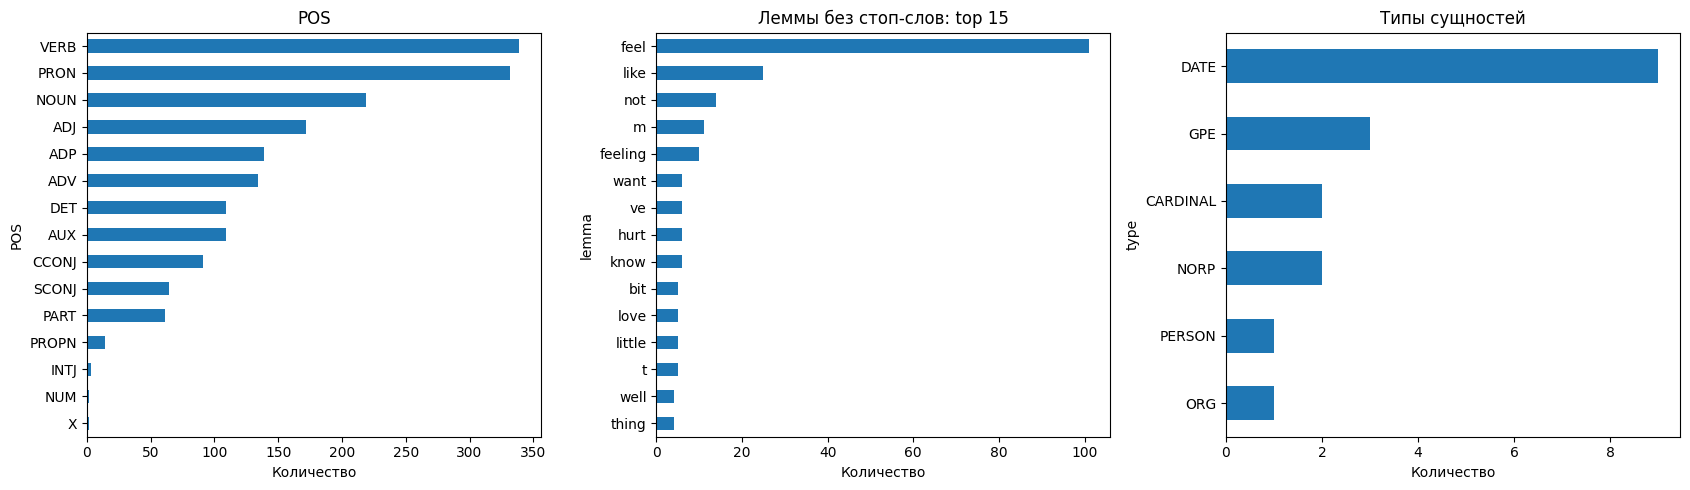

,count
POS,
VERB,339
PRON,332
NOUN,219
ADJ,172
ADP,139
ADV,134
AUX,109
DET,109
CCONJ,91


,count
lemma,
feel,101
like,25
not,14
m,11
feeling,10
want,6
know,6
hurt,6
ve,6


,count
type,
DATE,9
GPE,3
CARDINAL,2
NORP,2
PERSON,1
ORG,1


In [44]:
pos_counts = tokens_df['POS'].value_counts()
lemma_counts = tokens_df.loc[
    tokens_df['is_alpha'] & ~tokens_df['is_stop'], 'lemma'
].str.lower().value_counts().head(15)
entity_counts = entities_df['type'].value_counts()

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for counts, ax, title in zip(
    [pos_counts, lemma_counts, entity_counts], axes,
    ['POS', 'Леммы без стоп-слов: top 15', 'Типы сущностей'],
):
    counts.sort_values().plot.barh(ax=ax, title=title)
    ax.set_xlabel('Количество')
plt.tight_layout()
plt.show()
display(pos_counts.to_frame('count'), lemma_counts.to_frame('count'), entity_counts.to_frame('count'))

Шаг 4. Показываем разбор короткого текста и примеры сущностей с контекстом для обсуждения спорных результатов.

In [45]:
short_doc = min(sample_docs, key=len)
print(short_doc.text)
display(HTML(displacy.render(short_doc, style='dep', jupyter=False, options={'compact': True})))
entity_doc = max(sample_docs, key=lambda doc: len(doc.ents))
display(HTML(displacy.render(entity_doc, style='ent', jupyter=False)))
display(entities_df[['entity', 'type', 'context']].head(15))

i feel clever nov


,entity,type,context
0,a week,DATE,ive made it through a week i just feel beaten ...
1,mummy,PERSON,i feel like a crappy mummy if were stuck in bu...
2,new zealand,GPE,i am feeling so stunned and sad about the eart...
3,yesterday,DATE,i am feeling so stunned and sad about the eart...
4,ill crawl,ORG,ill crawl into the kitchen feeling miserable a...
5,chinese,NORP,i do have a chinese mum a few chinese sisters ...
6,chinese,NORP,i do have a chinese mum a few chinese sisters ...
7,two very important years,DATE,i do have a chinese mum a few chinese sisters ...
8,china,GPE,i do have a chinese mum a few chinese sisters ...
9,one,CARDINAL,i do have a chinese mum a few chinese sisters ...


### Задание 3. Постройте baseline для выбранного датасета

Для того же датасета соберите `Pipeline`:

```text
TfidfVectorizer → LogisticRegression
```

Используйте:

- готовые `train / test` splits из Hugging Face, если они есть;
- либо самостоятельно разделите данные.

Обучите и оцените модель по:

- Accuracy;
- Precision;
- Recall;
- F1.

Также постройте:

- confusion matrix.

В конце ответьте:

- какое качество получил baseline;
- есть ли дисбаланс классов;
- какие классы модель путает чаще всего и по какой причине;
- какие признаки, найденные через `spaCy`, потенциально могут улучшить модель.

---


Добавьте к TF-IDF признаки, полученные с помощью `spaCy`.

Например:

```text
TF-IDF
+
количество NOUN
+
количество VERB
+
доля ADJ
+
количество именованных сущностей
```

Обучите новую модель и сравните её с baseline.

Ответьте на вопрос:

```text
Улучшили ли лингвистические признаки качество модели?
```

Шаг 1. Используем официальные train/test и показываем баланс классов в обоих splits.

,train,test,train_share,test_share
sadness,4666,581,0.2916,0.2905
joy,5362,695,0.3351,0.3475
love,1304,159,0.0815,0.0795
anger,2159,275,0.1349,0.1375
fear,1937,224,0.1211,0.1120
surprise,572,66,0.0357,0.0330


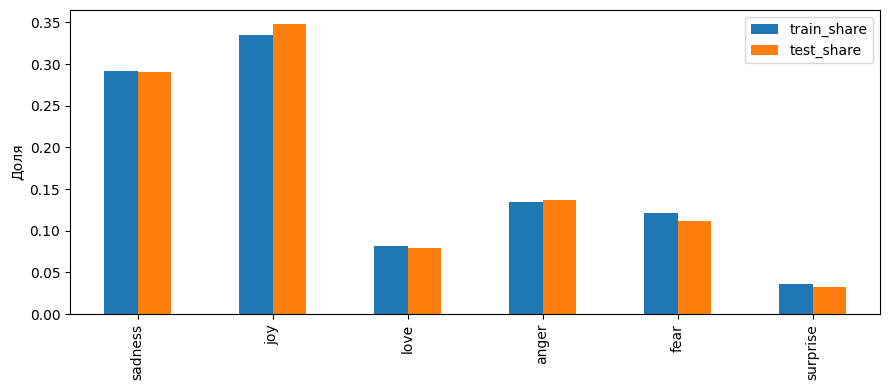

In [46]:
X_em_train = emotion_train_df['text']
y_em_train = emotion_train_df['label']
X_em_test = emotion_test_df['text']
y_em_test = emotion_test_df['label']
class_balance = pd.DataFrame({
    'train': y_em_train.value_counts().reindex(range(len(label_names))),
    'test': y_em_test.value_counts().reindex(range(len(label_names))),
})
class_balance.index = label_names
class_balance['train_share'] = class_balance['train'] / len(y_em_train)
class_balance['test_share'] = class_balance['test'] / len(y_em_test)
display(class_balance.round(4))
class_balance[['train_share', 'test_share']].plot.bar(figsize=(9, 4), ylabel='Доля')
plt.tight_layout()
plt.show()

Шаг 2. Обучаем TF-IDF → LogisticRegression на train и получаем прогнозы test.

In [47]:
hf_baseline = Pipeline([
    ('vectorizer', TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
    ('model', LogisticRegression(C=1.0, max_iter=1000, random_state=RANDOM_STATE)),
])
hf_baseline.fit(X_em_train, y_em_train)
hf_pred = hf_baseline.predict(X_em_test)

Шаг 3. Вычисляем Accuracy, macro-Precision/Recall/F1 и метрики по каждому классу; строим confusion matrix.

,baseline
accuracy,0.8305
precision_macro,0.8686
recall_macro,0.6774
f1_macro,0.7255


              precision    recall  f1-score   support

     sadness       0.86      0.91      0.89       581
         joy       0.78      0.97      0.86       695
        love       0.86      0.49      0.62       159
       anger       0.90      0.73      0.81       275
        fear       0.87      0.72      0.79       224
    surprise       0.94      0.24      0.39        66

    accuracy                           0.83      2000
   macro avg       0.87      0.68      0.73      2000
weighted avg       0.84      0.83      0.82      2000



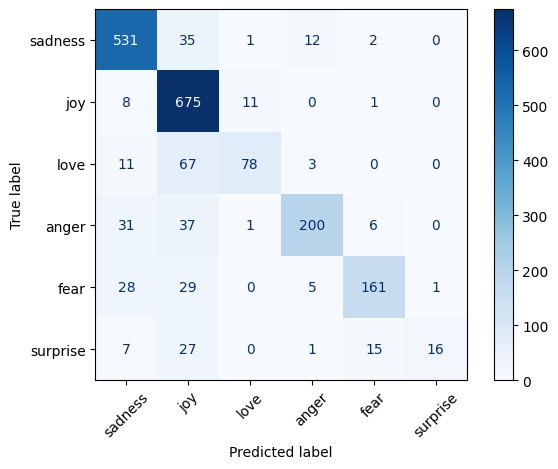

In [48]:
def classification_metrics(y_true, y_pred):
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average='macro', zero_division=0,
    )
    return {'accuracy': accuracy_score(y_true, y_pred),
            'precision_macro': precision, 'recall_macro': recall, 'f1_macro': f1}


baseline_metrics = classification_metrics(y_em_test, hf_pred)
display(pd.Series(baseline_metrics).to_frame('baseline').round(4))
print(classification_report(y_em_test, hf_pred, target_names=label_names, zero_division=0))
ConfusionMatrixDisplay.from_predictions(
    y_em_test, hf_pred, display_labels=label_names, cmap='Blues', xticks_rotation=45,
)
plt.tight_layout()
plt.show()

Шаг 4. Ранжируем пары ошибок и выводим тексты, истинный класс, прогноз и уверенность модели для устного анализа.

In [49]:
errors = emotion_test_df.loc[hf_pred != y_em_test.to_numpy(), ['text', 'label']].copy()
errors['actual'] = errors.pop('label').map(dict(enumerate(label_names)))
errors['predicted'] = [label_names[i] for i in hf_pred[hf_pred != y_em_test.to_numpy()]]
errors['confidence'] = hf_baseline.predict_proba(X_em_test).max(axis=1)[hf_pred != y_em_test.to_numpy()]
confused_pairs = errors.groupby(['actual', 'predicted']).size().sort_values(ascending=False)
display(confused_pairs.to_frame('count'))
display(errors.sort_values('confidence', ascending=False).head(15))
errors.to_csv(RESULTS / 'emotion_baseline_errors.csv', index=False)

count
actual   predicted       
love     joy           67
anger    joy           37
sadness  joy           35
anger    sadness       31
fear     joy           29
         sadness       28
surprise joy           27
         fear          15
sadness  anger         12
love     sadness       11
joy      love          11
         sadness        8
surprise sadness        7
anger    fear           6
fear     anger          5
love     anger          3
sadness  fear           2
anger    love           1
fear     surprise       1
joy      fear           1
sadness  love           1
surprise anger          1

,text,actual,predicted,confidence
265,i feel so blessed and honored that we get to b...,love,joy,0.730255
1154,i feel that passionate about,joy,love,0.706801
879,i feel more amazed and more thankful for havin...,surprise,joy,0.698516
796,im much more peaceful and happy when the house...,sadness,joy,0.694830
262,i realized what i am passionate about helping ...,joy,love,0.665591
1149,i feel so greedy so needy so helpless,anger,sadness,0.662274
302,i feel like now its more of sweet apple now,love,joy,0.650208
131,im feeling generous today heres one more you m...,love,joy,0.647165
193,i really dont like quinn because i feel like s...,anger,sadness,0.633792
1576,i cant do a simple math question and guess wha...,fear,sadness,0.633233


Шаг 5. Извлекаем числовые признаки spaCy для всех train/test текстов через `nlp.pipe`:
число NOUN/VERB, доля ADJ, число сущностей и число токенов.
Готовая языковая модель ничего не обучает на test. Масштабирование выполняется далее только по train.

In [50]:
ling_columns = ['n_noun', 'n_verb', 'adj_share', 'n_entities', 'n_tokens']


def linguistic_features(docs):
    return np.asarray([
        [sum(t.pos_ == 'NOUN' for t in doc),
         sum(t.pos_ == 'VERB' for t in doc),
         sum(t.pos_ == 'ADJ' for t in doc) / max(len(doc), 1),
         len(doc.ents), len(doc)]
        for doc in docs
    ], dtype=float)


ling_train = linguistic_features(nlp_en.pipe(X_em_train, batch_size=128))
ling_test = linguistic_features(nlp_en.pipe(X_em_test, batch_size=128))
train_with_ling = pd.DataFrame(ling_train, columns=ling_columns).assign(text=X_em_train.to_numpy())
test_with_ling = pd.DataFrame(ling_test, columns=ling_columns).assign(text=X_em_test.to_numpy())
display(train_with_ling.head())
display(train_with_ling.assign(label=y_em_train.to_numpy())
        .groupby('label')[ling_columns].mean().rename(index=dict(enumerate(label_names))).round(3))

,n_noun,n_verb,adj_share,n_entities,n_tokens,text
0,0.0,1.0,0.200000,0.0,5.0,i didnt feel humiliated
1,0.0,3.0,0.142857,0.0,21.0,i can go from feeling so hopeless to so damned...
2,1.0,3.0,0.181818,0.0,11.0,im grabbing a minute to post i feel greedy wrong
3,2.0,2.0,0.055556,0.0,18.0,i am ever feeling nostalgic about the fireplac...
4,0.0,1.0,0.250000,0.0,4.0,i am feeling grouchy


,n_noun,n_verb,adj_share,n_entities,n_tokens
label,,,,,
sadness,2.376,3.420,0.105,0.245,18.709
joy,2.719,3.431,0.107,0.268,19.814
love,3.002,3.655,0.090,0.243,21.012
anger,2.487,3.527,0.103,0.220,19.601
fear,2.454,3.496,0.112,0.191,19.183
surprise,2.778,3.523,0.108,0.252,20.309


Шаг 6. Объединяем TF-IDF и масштабированные признаки spaCy в ColumnTransformer.
Оставляем параметры TF-IDF и классификатора такими же, как у baseline, чтобы сравнить добавление признаков.

In [51]:
from sklearn.compose import ColumnTransformer

ling_pipeline = Pipeline([
    ('features', ColumnTransformer([
        ('text', clone(hf_baseline['vectorizer']), 'text'),
        ('ling', MaxAbsScaler(), ling_columns),
    ])),
    ('model', clone(hf_baseline['model'])),
])
ling_pipeline.fit(train_with_ling, y_em_train)
ling_pred = ling_pipeline.predict(test_with_ling)

Шаг 7. Сравниваем обе модели: общие метрики, прирост F1, F1 классов и матрицы ошибок.

,accuracy,precision_macro,recall_macro,f1_macro,delta_f1
TF-IDF,0.8305,0.8686,0.6774,0.7255,0.0000
TF-IDF + spaCy,0.8240,0.8599,0.6656,0.7117,-0.0138


,TF-IDF,TF-IDF + spaCy
class,,
sadness,0.8872,0.8867
joy,0.8626,0.8577
love,0.6240,0.6160
anger,0.8065,0.7879
fear,0.7873,0.7764
surprise,0.3855,0.3457


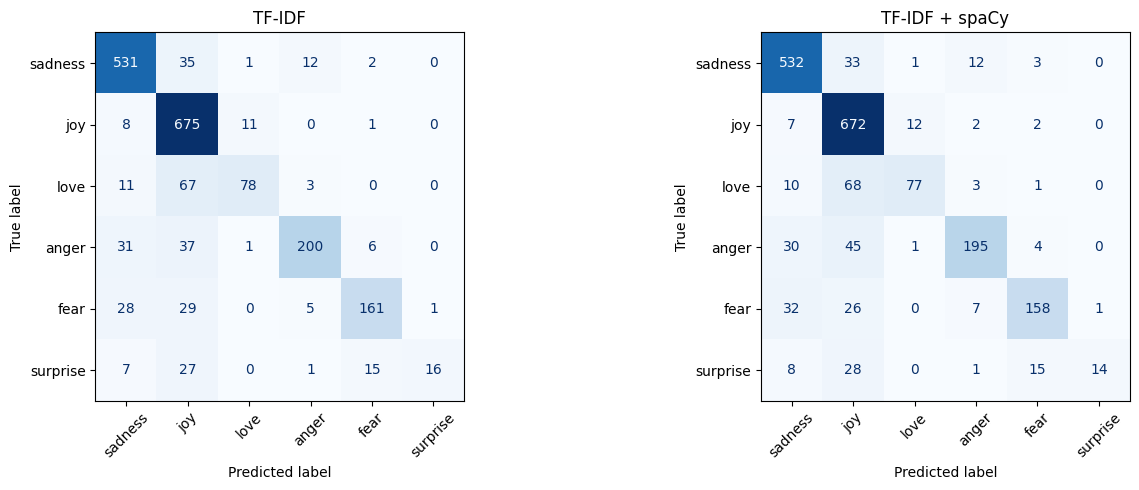

In [52]:
hf_comparison = pd.DataFrame({
    'TF-IDF': baseline_metrics,
    'TF-IDF + spaCy': classification_metrics(y_em_test, ling_pred),
}).T
hf_comparison['delta_f1'] = hf_comparison['f1_macro'] - baseline_metrics['f1_macro']
display(hf_comparison.round(4))
per_class_f1 = pd.DataFrame({
    'class': label_names,
    'TF-IDF': precision_recall_fscore_support(y_em_test, hf_pred, average=None, zero_division=0)[2],
    'TF-IDF + spaCy': precision_recall_fscore_support(y_em_test, ling_pred, average=None, zero_division=0)[2],
}).set_index('class')
display(per_class_f1.round(4))
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for pred, ax, title in zip([hf_pred, ling_pred], axes, hf_comparison.index):
    ConfusionMatrixDisplay.from_predictions(
        y_em_test, pred, display_labels=label_names, cmap='Blues', ax=ax,
        xticks_rotation=45, colorbar=False,
    )
    ax.set_title(title)
plt.tight_layout()
plt.show()
hf_comparison.to_csv(RESULTS / 'emotion_model_comparison.csv')
per_class_f1.to_csv(RESULTS / 'emotion_per_class_f1.csv')